# Análisis reproducible de DEAM

## Resultados utilizados en la presentación del recomendador musical emocional

Este notebook reproduce los indicadores descriptivos de la presentación a partir de `DEAM_Annotations.zip`. El análisis cubre inventario, cuadrantes de valencia-activación, subjetividad entre evaluadores y consistencia entre anotaciones estáticas y dinámicas.

El ZIP original está incluido en este mismo paquete. No es necesario extraerlo manualmente.

## 1. Configuración y carga de funciones

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

PACKAGE_ROOT = Path.cwd()
if not (PACKAGE_ROOT / "DEAM_Annotations.zip").exists():
    # Permite ejecutar el notebook desde Jupyter abierto en otra carpeta.
    PACKAGE_ROOT = Path(".").resolve()

sys.path.insert(0, str(PACKAGE_ROOT / "src"))
from analisis_deam import load_deam, compute_analysis, validate_results

ZIP_PATH = PACKAGE_ROOT / "DEAM_Annotations.zip"
OUTPUT_DIR = PACKAGE_ROOT / "outputs"
print(f"Fuente: {ZIP_PATH.resolve()}")

Fuente: /workspace/scratch/6be7af4e0e18/output/DEAM_analisis_reproducible/DEAM_Annotations.zip


## 2. Ejecución y validación

In [2]:
data = load_deam(ZIP_PATH)
analysis = compute_analysis(data)
validate_results(analysis)

metrics = analysis["metrics"]
print("Validación completada")
print(f"Canciones: {metrics['songs']:,}")
print(f"Valoraciones individuales: {metrics['individual_ratings']:,}")
print(f"Evaluadores únicos: {metrics['unique_raters']:,}")
print(f"Archivos CSV: {metrics['csv_files']:,}")
print(f"Frecuencia dinámica: {metrics['sampling_frequency_hz']:.0f} Hz")

Validación completada
Canciones: 1,802
Valoraciones individuales: 17,762
Evaluadores únicos: 195
Archivos CSV: 3,610
Frecuencia dinámica: 2 Hz


## 3. Resumen de los indicadores de la presentación

In [3]:
results = pd.read_csv(OUTPUT_DIR / "resultados_presentacion.csv")
display(results)

                                     indicador    resultado     unidad
                        Canciones o fragmentos  1802.000000     conteo
                     Valoraciones individuales 17762.000000     conteo
                            Evaluadores únicos   195.000000     conteo
                                  Archivos CSV  3610.000000     conteo
            Mediana de evaluadores por canción    10.000000     conteo
                           Frecuencia dinámica     2.000000         Hz
                                Valencia media     4.904145 escala 1-9
                              Activación media     4.814029 escala 1-9
               Correlación valencia-activación     0.570026  Pearson r
  Desviación media entre evaluadores: valencia     1.502364 desviación
Desviación media entre evaluadores: activación     1.462719 desviación
    Canciones con desviación de valencia > 1.5    49.556049          %
  Canciones con desviación de activación > 1.5    45.560488          %
      

### Lectura principal

- Las 1.802 canciones tienen etiquetas emocionales estáticas y dinámicas.
- Las 17.762 valoraciones provienen de 195 evaluadores únicos.
- La anotación dinámica tiene intervalos de 500 ms, equivalentes a 2 Hz.
- El ZIP contiene 3.610 archivos CSV y no incluye audio.

## 4. Distribución por cuadrantes emocionales

       quadrant  songs  percentage
Negativa / baja    686   38.068812
Positiva / alta    647   35.904550
Positiva / baja    240   13.318535
Negativa / alta    229   12.708102


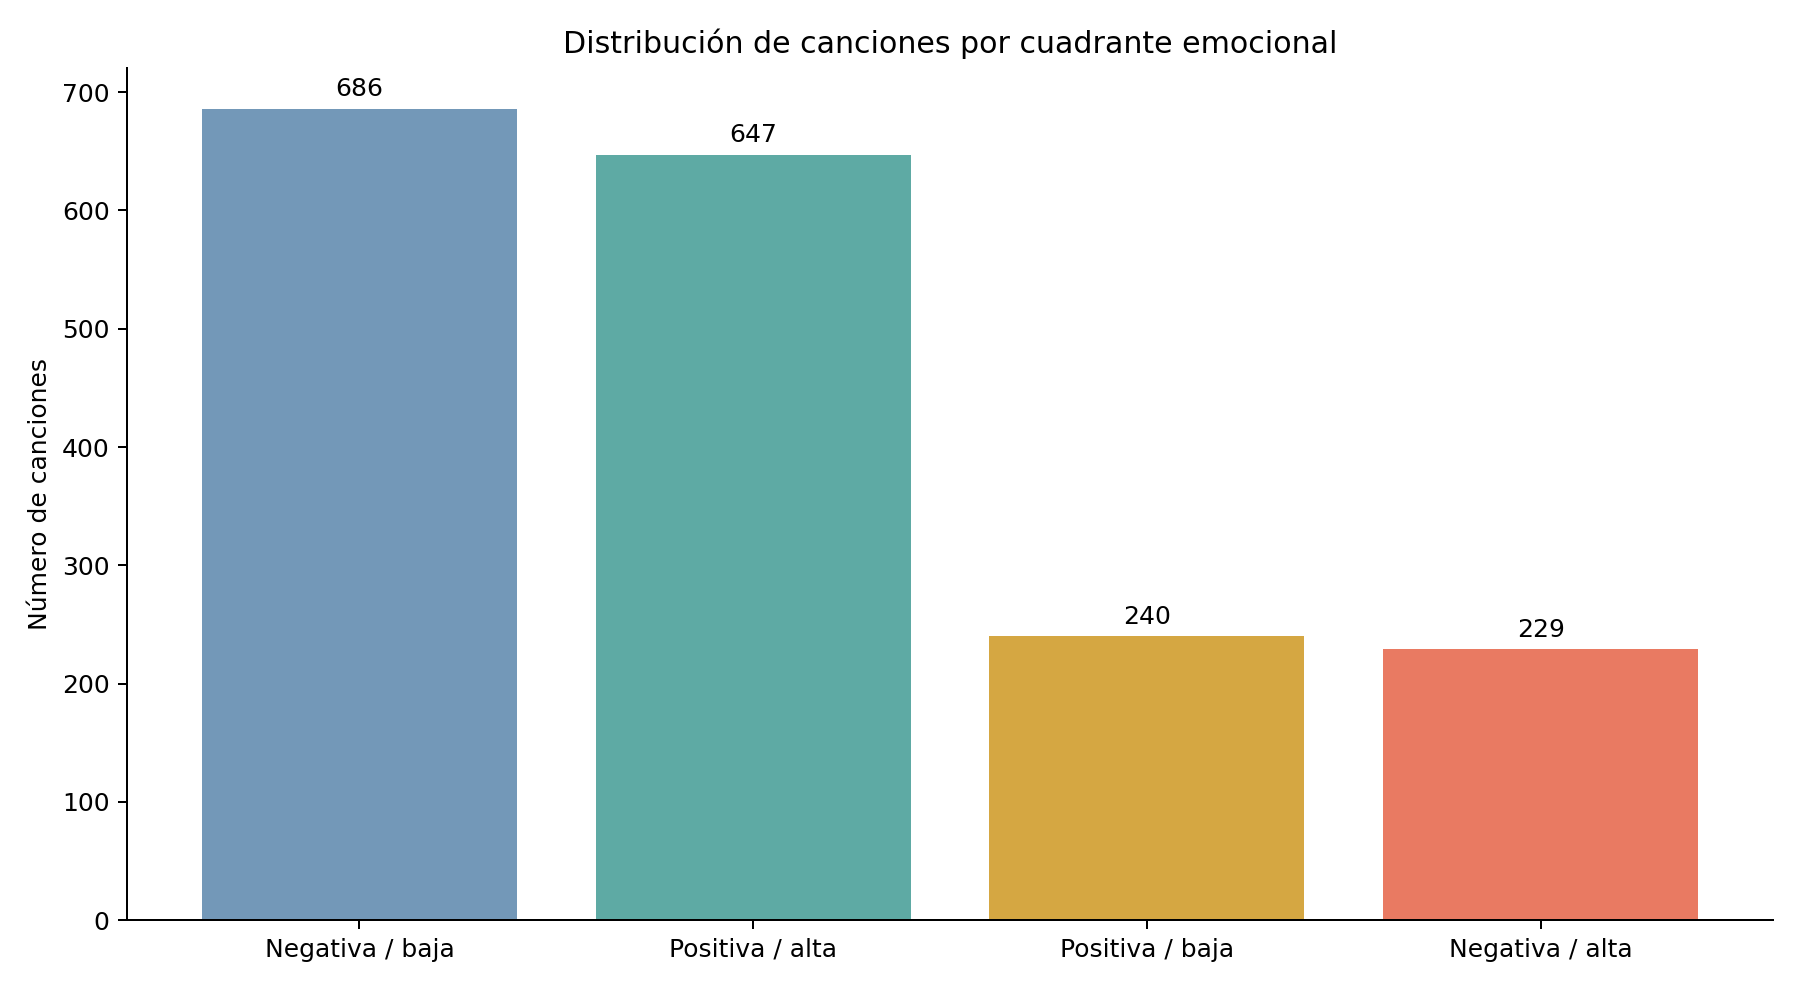

In [4]:
quadrants = analysis["quadrants"]
display(quadrants)
display(Image(filename=str(OUTPUT_DIR / "01_distribucion_cuadrantes.png")))

Los cuadrantes negativa/baja y positiva/alta reúnen aproximadamente el 74 % del catálogo. Por esta razón, la partición de entrenamiento debe conservar la distribución y el desempeño debe reportarse por región emocional.

## 5. Espacio de valencia y activación

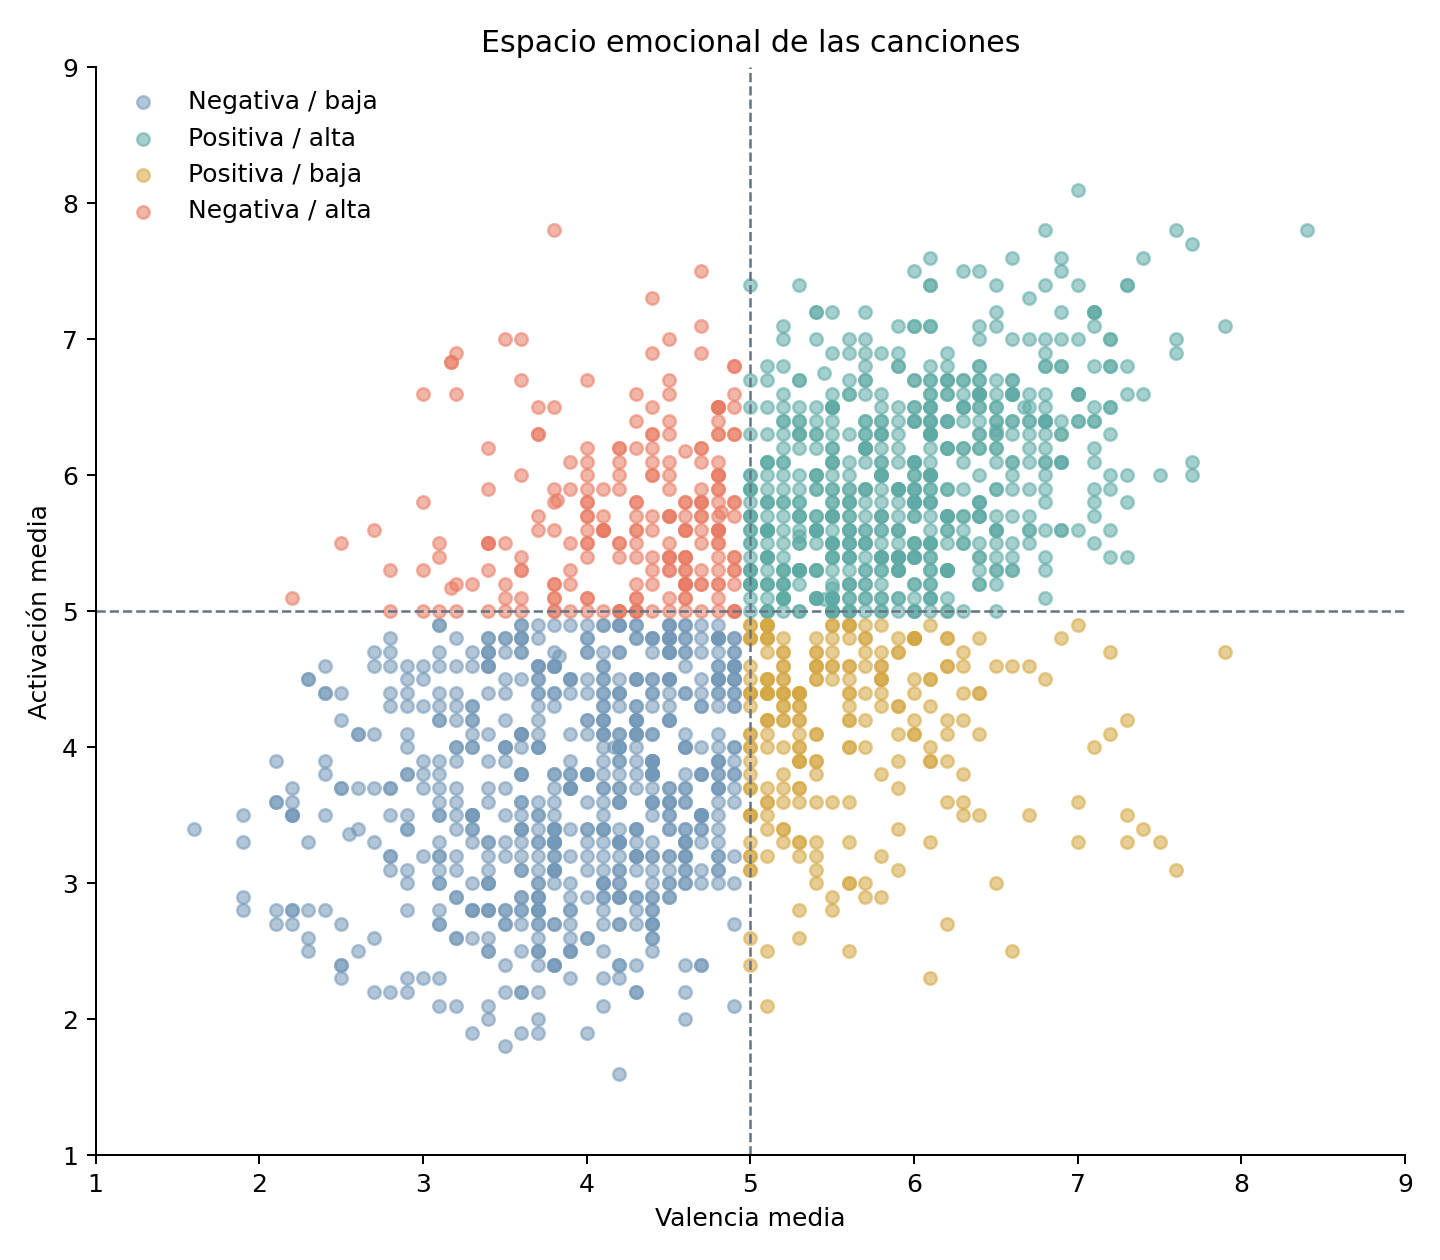

Correlación valencia-activación: 0.570


In [5]:
display(Image(filename=str(OUTPUT_DIR / "02_espacio_valencia_activacion.png")))
print(f"Correlación valencia-activación: {metrics['valence_arousal_correlation']:.3f}")

## 6. Subjetividad emocional

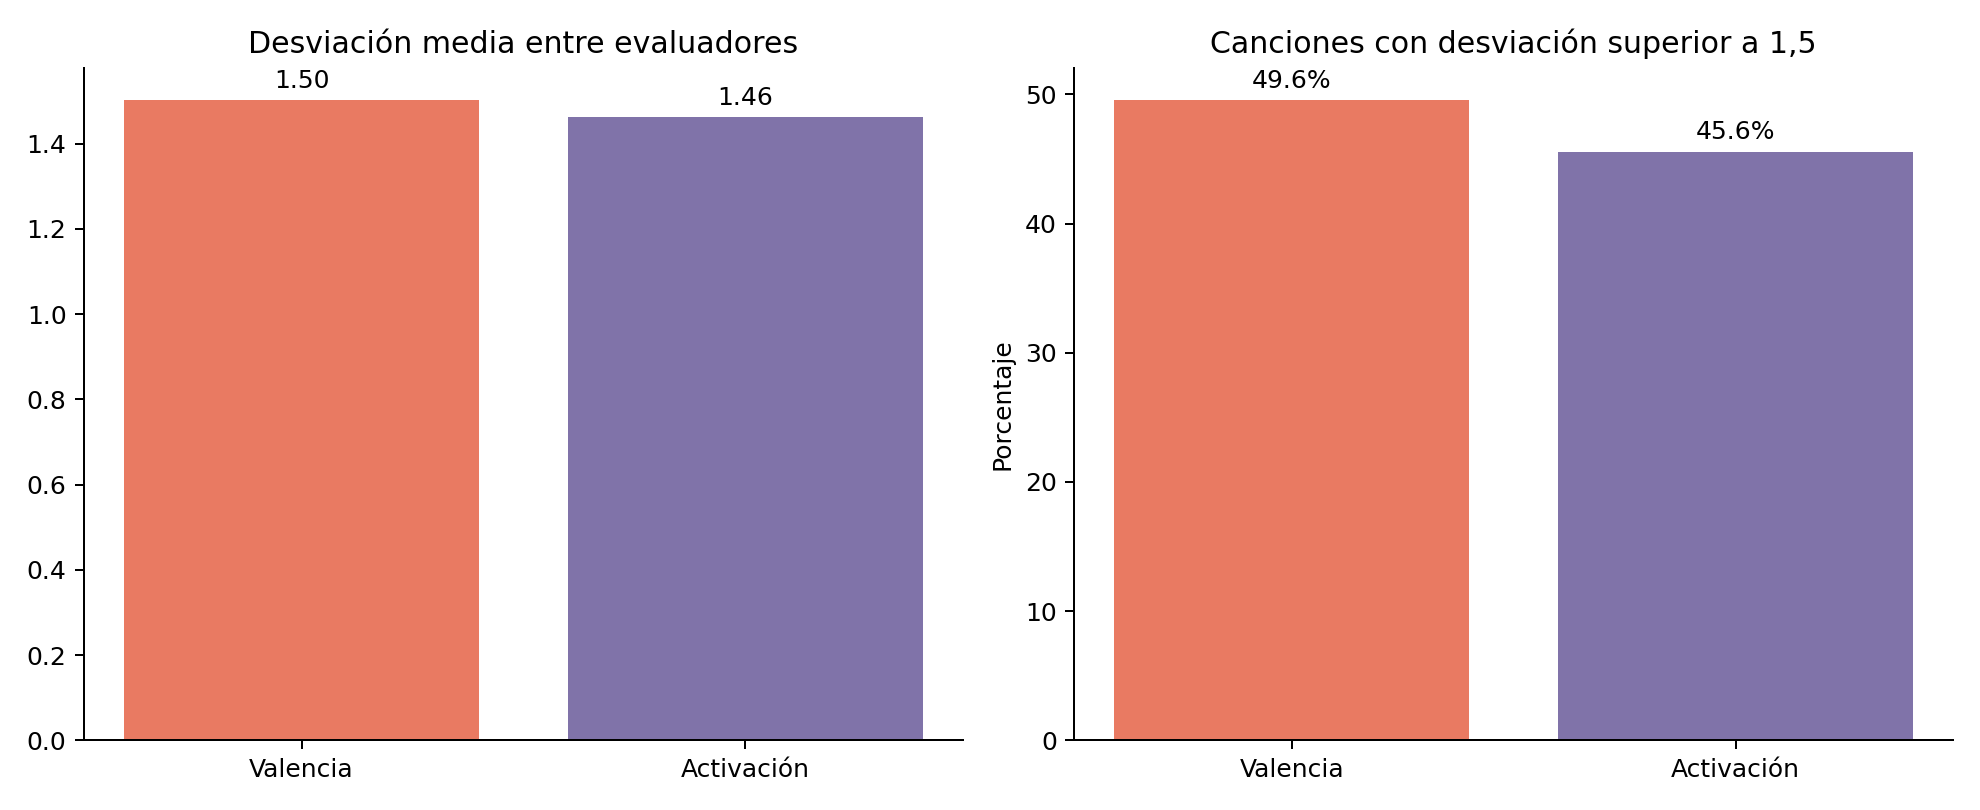

Desviación media de valencia: 1.50
Desviación media de activación: 1.46
Valencia con desviación > 1.5: 49.6%
Activación con desviación > 1.5: 45.6%


In [6]:
display(Image(filename=str(OUTPUT_DIR / "03_subjetividad_emocional.png")))
print(f"Desviación media de valencia: {metrics['mean_interrater_valence_sd']:.2f}")
print(f"Desviación media de activación: {metrics['mean_interrater_arousal_sd']:.2f}")
print(f"Valencia con desviación > 1.5: {metrics['valence_sd_over_1_5_pct']:.1f}%")
print(f"Activación con desviación > 1.5: {metrics['arousal_sd_over_1_5_pct']:.1f}%")

La variación entre evaluadores no se trata únicamente como ruido. Es evidencia de que la percepción musical cambia entre personas y justifica incorporar incertidumbre y personalización.

## 7. Consistencia entre anotaciones estáticas y dinámicas

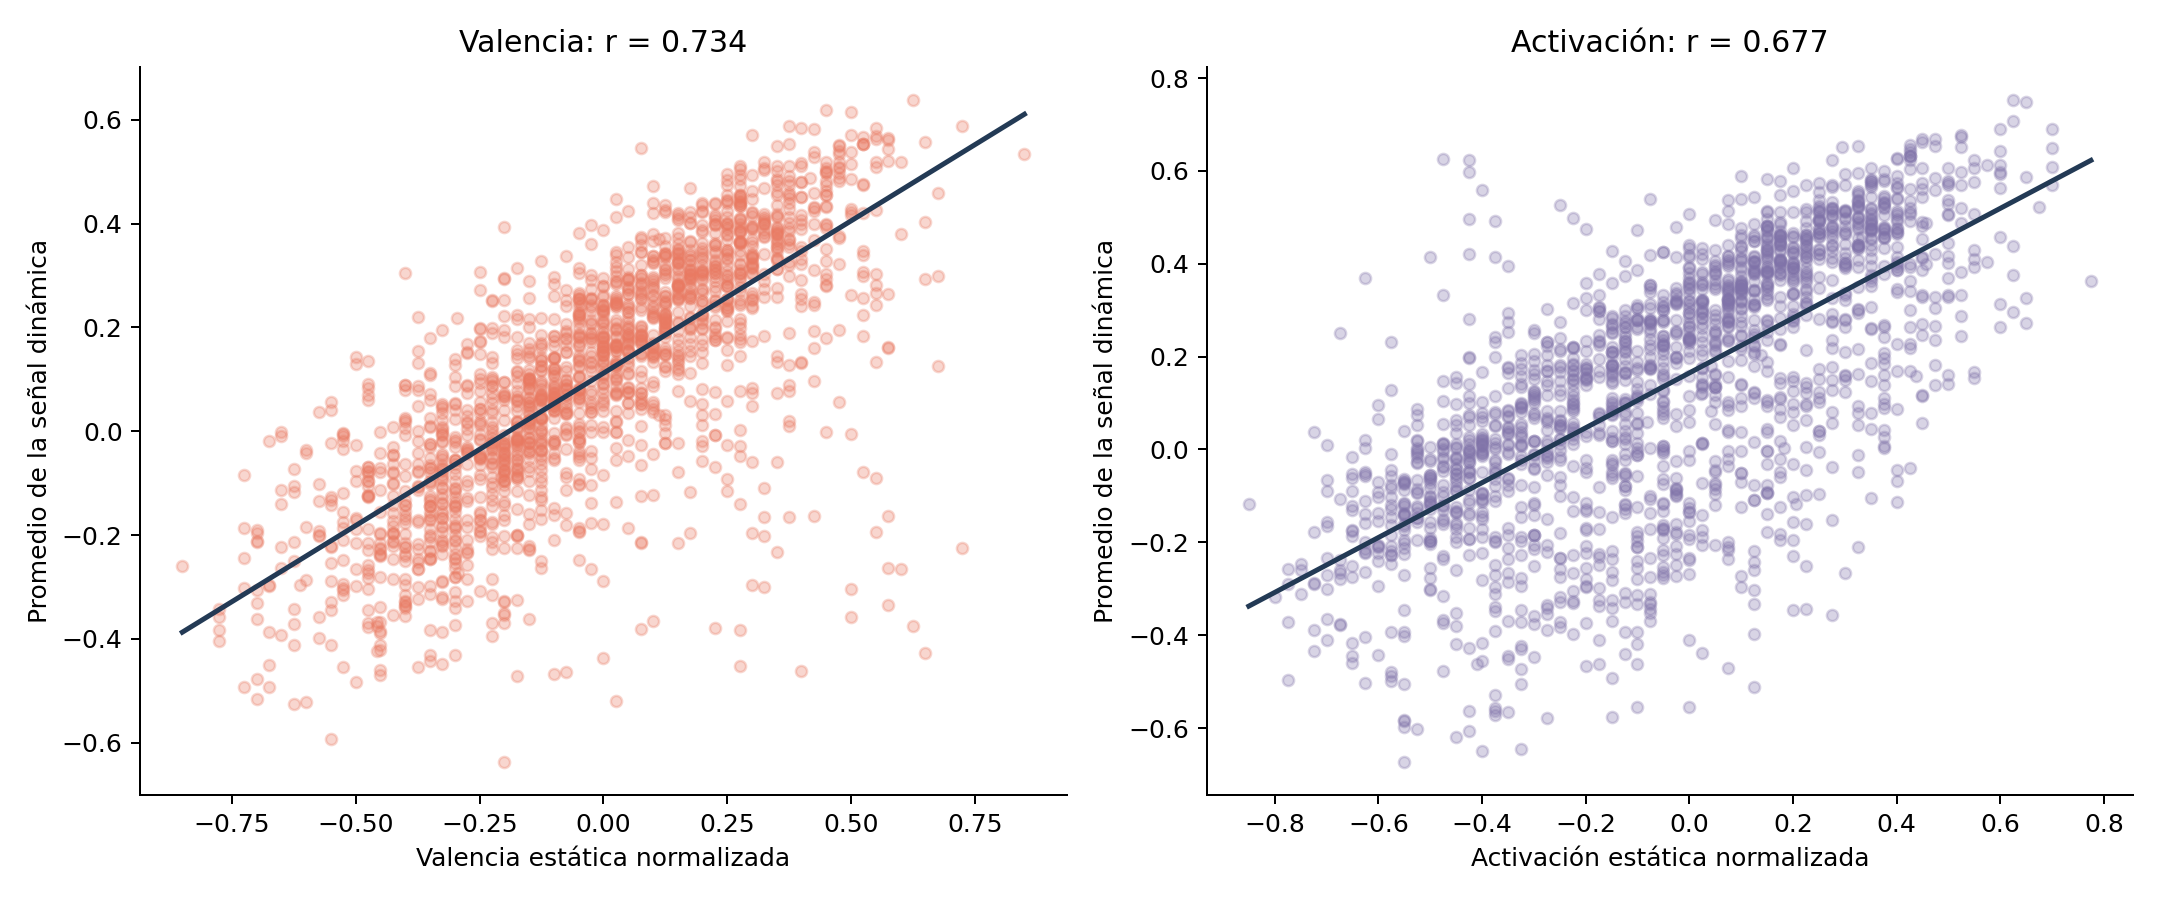

Valencia: r = 0.734
Activación: r = 0.677


In [7]:
display(Image(filename=str(OUTPUT_DIR / "04_consistencia_estatica_dinamica.png")))
print(f"Valencia: r = {metrics['static_dynamic_valence_correlation']:.3f}")
print(f"Activación: r = {metrics['static_dynamic_arousal_correlation']:.3f}")

## 8. Conclusión metodológica

Los resultados respaldan un MVP basado en valencia, activación y recomendación por contenido. El análisis también identifica dos condiciones para evolucionar el sistema:

1. **Transfer learning:** requiere acceso a los archivos de audio y validación de su licencia.
2. **Modelo híbrido personalizado:** requiere interacciones usuario-canción recolectadas mediante un piloto.

El archivo suministrado permite reproducir el componente emocional, pero no contiene audio ni historial de escucha.